<a href="https://colab.research.google.com/github/shahad030/Final-Project--Bayan-bilingual-citizen-feedback/blob/main/Copy_of_New_Day3_Bayan_Integrated_STUDENT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 3 — Bayan Understands Arabic, Finds Cases, Proves Quality (Student version)
# اليوم الثالث — بيان يفهم العربية، يجد الحالات المشابهة، ويُثبت الجودة (نسخة الطالب)
**SDA-AIE-211**

## القصة | The story
- 🇸🇦 لاحظ فريق العمليات ثلاث مشاكل: (أ) اللهجات لا تُعامل بالتساوي، (ب) الموظفون لا يجدون الحالات السابقة المشابهة بسرعة، (ج) المديرون يريدون **دليلًا** على جودة النموذج. مهمتكم حل المشاكل الثلاث.
- 🇬🇧 Operations found three problems: (A) dialects aren't treated equally, (B) agents can't quickly find similar past cases, (C) managers want **evidence** of quality. Your team fixes all three.


## الخطوات | Steps
| # | الخطوة | Step |
|---|---|---|
| **A** | **العربية واللهجات** | **Arabic and dialects** |
| 1 | تجهيز النص العربي | Prepare Arabic text |
| 2 | تدقيق اللهجات | Dialect audit |
| 3 | الحروف الملتصقة | Attached letters (clitics) |
| 4 | أداء لهجة الخليج | Gulf dialect performance |
| 5 | مقارنة نماذج عربية (اختياري) | Arabic model bake-off (optional) |
| **B** | **البحث الدلالي** | **Semantic search** |
| 6 | بناء الفهرس | Build the index |
| 7 | جرّب البحث | Try searching |
| 8 | قياس الجودة | Measure quality |
| 9 | إعادة الترتيب | Re-ranking |
| 10 | حد "لا توجد حالة" | The "no case" threshold |
| 11 | الخطأ المخفي | The planted bug |
| **C** | **التقييم وتحليل الأخطاء** | **Evaluation and errors** |
| 12 | فاصل الثقة | Confidence interval |
| 13 | الشرائح | Slices |
| 14 | اختبارات السلوك | Behaviour tests |
| 15 | مراجعة الأخطاء | Error review |
| 16 | بطاقة النموذج والقرارات | Model card and decisions |

📥 **يقرأ / Reads:** نتائج Lab 3a في مجلد الدفتر: `day2_topic_test_predictions.csv` و`day2_validation_errors.csv` + النموذج `bayan_topic_model`
📤 **ينتج / Produces:** `bayan_cases.faiss` · `slice_report.csv` · `120_error_review.csv` · `topic_model_card.json` · `DECISIONS_day3.md`
⏱️ 150 min

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## تشغيل محلي (VS Code) | Local run (VS Code)
- 🇸🇦 ضع الدفتر وملفات البيانات في **مجلد واحد**، وافتحه في VS Code، واختر Python Kernel. أول خليتين تثبّتان المكتبات تلقائيًا (أول مرة فقط، وتحتاج إنترنت). خلية الإعداد تطبع الملفات الموجودة والناقصة.
- 🇬🇧 Put the notebook and the data files in **one folder**, open it in VS Code and pick a Python kernel. The first two cells install the libraries (first run only, needs internet). The setup cell prints which files are present or missing.
- 📄 الملفات | Files: `bayan_feedback_clean.csv` · `bayan_cases.csv` · `bayan_queries.jsonl` · `day2_topic_test_predictions.csv` · `day2_validation_errors.csv` (+ `bayan_topic_model/` اختياري | optional)
- ✍️ ابحث عن `TODO` في الخلايا: اقرأ المطلوب واكتب إجابتك في التعليق تحت «إجابتي | My answer».
- ✍️ Search for `TODO` in the cells: read the task and write your answer in the comment under "My answer".

## Setup — تجهيز
- 🇸🇦 نثبّت المكتبات، ونحمّل البيانات، ونتأكد أن نتائج Lab 3a موجودة.
- 🇬🇧 Install libraries, load the data, and check that the Lab 3a results are there.

In [2]:
%pip -q install camel-tools

# تحميل بيانات CAMeL (اختياري) | download CAMeL data (optional: this cell never stops the run)
import subprocess, sys, shutil
from pathlib import Path
camel_data = shutil.which('camel_data') or str(Path(sys.executable).parent / ('camel_data.exe' if sys.platform == 'win32' else 'camel_data'))
try:
    subprocess.run([camel_data, '-i', 'morphology-db-msa-r13'], check=True)
except Exception as exc:
    print('CAMeL data not installed (optional step):', exc)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
# قد يستغرق عدة دقائق (torch كبيرة) | may take several minutes (torch is large)
%pip -q install pandas numpy scikit-learn torch transformers sentence-transformers faiss-cpu

In [13]:
from pathlib import Path
import zipfile, json, re, time
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# ✍️ TODO 0: إن كانت الملفات في مكان آخر ضع مسار المجلد كاملًا داخل Path("..."). Path.cwd() = مجلد هذا الدفتر.
#            If your files are elsewhere, put the full folder path inside Path("..."). Path.cwd() = the folder of this notebook.
#            شغّل الخلية: يجب أن تظهر كل الملفات OK | Run the cell: every file should say OK.
DATA_DIR = Path("/content/drive/MyDrive/NATURAL LANGUAGE PROCESSING WITH TRANSFORMER/Data")

# results go to a writable local folder (the Drive "Data" folder was read-only in Lab 1)
ARTIFACT_DIR = Path('/content/artifacts')
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# check the required files
print('Looking for files in / مكان البحث:', DATA_DIR.resolve())
for name in ['bayan_feedback_clean.csv', 'bayan_cases.csv', 'bayan_queries.jsonl',
             'day2_topic_test_predictions.csv', 'day2_validation_errors.csv']:
    print('OK     ' if (DATA_DIR / name).exists() else 'MISSING', name)

print('Model folder bayan_topic_model:',
      'OK' if (DATA_DIR / 'bayan_topic_model').exists() else 'missing (optional)')


feedback = pd.read_csv('/content/bayan_feedback_clean.csv')
print('Rows / عدد الصفوف:', len(feedback))



Looking for files in / مكان البحث: /content/drive/.shortcut-targets-by-id/1-vfyPhMTdOHfuv5cox1F4IPardyh6B0c/NATURAL LANGUAGE PROCESSING WITH TRANSFORMER/Data
MISSING bayan_feedback_clean.csv
OK      bayan_cases.csv
OK      bayan_queries.jsonl
OK      day2_topic_test_predictions.csv
OK      day2_validation_errors.csv
Model folder bayan_topic_model: OK
Rows / عدد الصفوف: 12000


# Part A — العربية واللهجات | Arabic and dialects

## Step 1 — تجهيز النص العربي | Prepare Arabic text
- 🇸🇦 كل نموذج يتوقع شكلًا مختلفًا للنص. **CAMeLBERT** يحتاج توحيد الألف والتاء المربوطة وحذف التشكيل. أما **XLM-R** فيكفيه التنظيف العام.
- 🇬🇧 Each model expects different text. **CAMeLBERT** needs unified alef / teh-marbuta and no diacritics. **XLM-R** only needs generic cleaning.
- 🇸🇦 نحتفظ بالنص الأصلي للعرض، ونصنع **نسخة للنموذج**. الدالة بسيطة ومعها **اختبارات ذهبية** (Golden tests) تتأكد أنها صحيحة.
- 🇬🇧 Keep the original for display and make a separate **model copy**. The function is short and comes with **golden tests** that prove it works.

In [16]:
# ✍️ TODO 1: أضف اختبارًا ذهبيًا سادسًا إلى القائمة golden أدناه، مثال: ('إلى', 'الي') ثم شغّل الخلية.
#            Add a 6th golden test to the list `golden` below, then run the cell.


# ---------- 🔒 (للقراءة فقط | read-only) ----------
def normalize_arabic(text, profile):
    text = re.sub(r'\s+', ' ', str(text).replace('ـ', '')).strip()     # حذف التطويل وتوحيد المسافات | remove tatweel, fix spaces
    if profile == 'camelbert':
        text = text.translate(str.maketrans({'أ': 'ا', 'إ': 'ا', 'آ': 'ا', 'ى': 'ي', 'ة': 'ه'}))   # توحيد الحروف | unify letters
        text = re.sub(r'[ً-ٰٟ]', '', text)                                          # حذف التشكيل | remove diacritics
    return text          # 'xlmr' يبقى كما هو بعد التنظيف العام | stays as is after generic cleaning

# ---------- 🔒 اختبارات ذهبية | golden tests ----------
golden = [('أحمد', 'احمد'), ('مدرسة', 'مدرسه'), ('على', 'علي'), ('الْكِتَابُ', 'الكتاب'), ('الخدمــة', 'الخدمه'),
('إدارة', 'اداره')]
for raw, expected in golden:
  # Check whether the actual output matches the expected output. assert means: تأكد أن الناتج الفعلي يساوي الناتج المتوقع
    assert normalize_arabic(raw, 'camelbert') == expected, (raw, normalize_arabic(raw, 'camelbert'), expected)
print('✅ Golden tests passed:', len(golden), '/', len(golden))

sample = feedback.loc[feedback.language == 'ar', 'text'].iloc[0]
print('Raw        :', sample)
print('CAMeLBERT  :', normalize_arabic(sample, 'camelbert'))

ARABIC_PROFILE = 'xlmr'
print('Our copy   :', normalize_arabic(sample, ARABIC_PROFILE))

✅ Golden tests passed: 6 / 6
Raw        : للعلم، اضطررنا لطلب وايت لأن الصنابير جافة. أرجو الإفادة.
CAMeLBERT  : للعلم، اضطررنا لطلب وايت لان الصنابير جافه. ارجو الافاده.
Our copy   : للعلم، اضطررنا لطلب وايت لأن الصنابير جافة. أرجو الإفادة.


## Step 2 — تدقيق اللهجات | Dialect audit
- 🇸🇦 كم نسبة كل لهجة؟ إن كانت لهجة قليلة فقد يكون أداء النموذج عليها أضعف، وإن قسنا على الفصحى فقط فلن نرى المشكلة.
- 🇬🇧 What share does each dialect have? A small dialect often means weaker performance, and if we only measure on MSA we never see the problem.

dialect_region
Gulf         48.1
MSA          27.6
Levantine    12.5
Egyptian     11.8
Name: proportion, dtype: float64


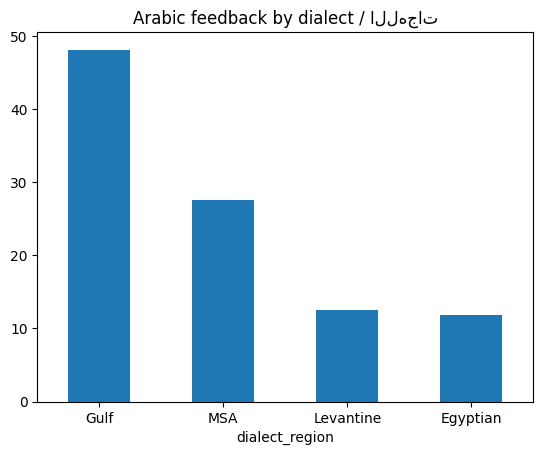

In [18]:
# ✍️ TODO 2: بعد التشغيل: ما اللهجة الأقل نسبة؟ ولماذا قد يكون أداء النموذج عليها أضعف؟
#            After running: which dialect has the smallest share, and why might the model be weaker on it?
# إجابتي | My answer:
# Egyptian has the smallest share (about 11.8%, 710 of 6,000 Arabic rows),
# and Levantine is close behind (12.5%).
# The model may be weaker on it because it sees far fewer Egyptian examples during
# training, and Egyptian uses its own words and forms (for example "مش بيشتغل", "لسه")
# that are different from MSA and Gulf. A small slice is also a noisy one: its
# score moves a lot with a few examples, so its confidence interval is wide.
# This is what I expect, not something I measured yet. Step 4 will show it.
arabic = feedback[feedback.language == 'ar']
dialect_pct = (arabic.dialect_region.value_counts(normalize=True) * 100).round(1) #normalize=True convert to percentage
print(dialect_pct)
dialect_pct.plot(kind='bar', title='Arabic feedback by dialect / اللهجات', rot=0); #rot = 	جعل أسماء اللهجات أفقية دون تدوير

## Step 3 — الحروف الملتصقة | Attached letters (clitics)
- 🇸🇦 في العربية تلتصق الحروف بالكلمة: "وبالرياض" = و + ب + ال + رياض. النموذج يفهم أفضل إذا فصلناها، وبالطريقة نفسها في التدريب والتشغيل.
- 🇬🇧 In Arabic, letters attach to the word: "وبالرياض" = و + ب + ال + رياض. The model understands better when we split them — the same way in training and serving.
- 🔒 نستخدم أداة جاهزة **CAMeL Tools** (`d3tok`). إن لم تتوفر يظهر شرح توضيحي فقط.
- 🔒 We use the ready-made **CAMeL Tools** (`d3tok`). If it is not installed, you see an illustration only.

In [22]:
# ✍️ TODO 3: غيّر sample_clitic إلى جملة من عندك فيها حرف ملتصق (و / ب / ل / ال) وشغّل الخلية، ثم صف كيف قُطّعت الكلمة.
#            Change sample_clitic to your own sentence with an attached letter and describe the split.
#            (إن ظهرت رسالة "not ready" فهذا مقبول: الخطوة اختيارية | "not ready" is OK: optional step)
# إجابتي | My answer:
# My sentence: "تأخر الطلب وللمرة الثالثة لم يصل".
# d3tok split "وللمرة" into و+ ، ل+ ، ال+ ، مرة (conjunction, preposition, article, stem),
# even though in writing "ل" and "ال" are merged into "لل". It also split the article
# from "الطلب" (ال+ طلب) and "الثالثة" (ال+ ثالثة).
# The verbs "تأخر" and "يصل" and the negation word "لم" stayed whole, so the negation is kept.
# Same segmentation must be used in training and serving.

!camel_data -i disambig-mle-calima-msa-r13
sample_clitic = 'تأخر الطلب وللمرة الثالثة لم يصل'
try:
    from camel_tools.disambig.mle import MLEDisambiguator
    from camel_tools.tokenizers.morphological import MorphologicalTokenizer
    from camel_tools.tokenizers.word import simple_word_tokenize
    morph = MorphologicalTokenizer(MLEDisambiguator.pretrained(), scheme='d3tok', split=True) #اختيار طريقة التقطيعscheme='d3tok .
    print('d3tok:', morph.tokenize(simple_word_tokenize(sample_clitic)))
except Exception as exc:
    print('CAMeL Tools not ready (optional):', exc)
    print('Illustration: وبالرياض -> و+ ب+ ال+ رياض')
print('Rule / قاعدة: نفس التقطيع وقت التدريب ووقت التشغيل | same segmentation in training and serving.')

No new packages will be installed.
d3tok: ['تأخر', 'ال+', 'طلب', 'و+', 'ل+', 'ال+', 'مرة', 'ال+', 'ثالثة', 'لم', 'يصل']
Rule / قاعدة: نفس التقطيع وقت التدريب ووقت التشغيل | same segmentation in training and serving.


## Step 4 — أداء لهجة الخليج | Gulf dialect performance
- 🇸🇦 نقارن أداء نموذج Day 2 على **كل لهجة** من ملف التنبؤات. نستخدم دالة جاهزة `slice_table` نعيد استخدامها لاحقًا.
- 🇬🇧 We compare the Day 2 model on **each dialect** using the predictions file. We use a ready function `slice_table` that we reuse later.

Columns / الأعمدة: ['feedback_id', 'citizen_id', 'language', 'dialect_region', 'topic', 'sentiment', 'created_day', 'text', 'y_true', 'prediction', 'source']
Overall macro-F1 / الأداء العام: 0.814


,dialect_region,n,macro_f1
0,Egyptian,178,0.700
1,Gulf,508,0.808
2,Levantine,167,0.804
3,MSA,253,0.804


Gulf rows / صفوف الخليج: 508


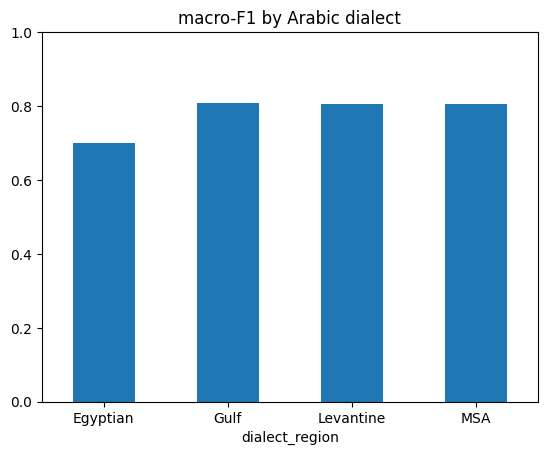

In [24]:
# ✍️ TODO 4: من جدول dialect_scores: أي لهجة لها أقل macro_f1؟ وكم عدد أمثلتها (n)؟ هل يمكن أن تكون قلة الأمثلة سببًا؟
#            From dialect_scores: which dialect has the lowest macro_f1, how many samples (n)? Could few samples be the reason?
# إجابتي | My answer:
#Egyptian has the lowest macro-F1: 0.700, with n = 178 samples
# (Gulf 0.808 with n = 508, Levantine 0.804, MSA 0.804).
# Few samples may be part of the reason, because a small slice gives a noisy score.
# But it can't be the whole reason: Levantine has fewer samples (167) and still scores 0.804,
# and its training share is almost the same as Egyptian's (12.5% vs 11.8%).
# So the gap probably also comes from the dialect itself. I would check it with a
# confidence interval (Step 12) before drawing a firm conclusion.

pred = pd.read_csv(DATA_DIR / 'day2_topic_test_predictions.csv')
print('Columns / الأعمدة:', list(pred.columns))

# ---------- 🔒 دوال جاهزة | ready functions ----------
def macro_f1(frame):
    return f1_score(frame.y_true, frame.prediction, average='macro')

def slice_table(frame, column): #ا تقسيم البيانات إلى مجموعات حسب عمود معين، ثم حساب Macro-F1 لكل مجموعة
    rows = [{column: name, 'n': len(g), 'macro_f1': round(macro_f1(g), 3)} #n = number of samples
            for name, g in frame.groupby(column, observed=True)]
    return pd.DataFrame(rows)

print('Overall macro-F1 / الأداء العام:', round(macro_f1(pred), 3))
pred_ar = pred[pred.language == 'ar']
dialect_scores = slice_table(pred_ar, 'dialect_region')
display(dialect_scores)
dialect_scores.set_index('dialect_region').macro_f1.plot(kind='bar', ylim=(0, 1), title='macro-F1 by Arabic dialect', rot=0);

gulf = pred[pred.dialect_region == 'Gulf']
print('Gulf rows / صفوف الخليج:', len(gulf))

# Part B — البحث الدلالي | Semantic search
**القصة / Story:** 🇸🇦 وصلت شكوى جديدة؛ يريد الموظف رؤية حالة مشابهة **محلولة**، حتى لو كُتبت بلغة مختلفة. 🇬🇧 A new complaint arrives; the officer wants a similar **resolved** case, even if written in another language.

**هدف هذا الجزء:**
1. تحويل الحالات إلى Embeddings.
2. تخزينها في FAISS والبحث عن أقرب الحالات.
3. قياس جودة البحث باستخدام Recall@10 و MRR@10.
4. فهم Re-ranking و No-answer threshold.
5. ملاحظة أهمية تطبيع المتجهات.

In [25]:
from sentence_transformers import SentenceTransformer
import faiss
import json
import numpy as np
import pandas as pd
import time

# تحميل الحالات والاستفسارات | load the cases and the judged queries
cases = pd.read_csv(DATA_DIR / 'bayan_cases.csv')
queries = [json.loads(line) for line in open(DATA_DIR / 'bayan_queries.jsonl', encoding='utf-8') if line.strip()]
print("Cases:", len(cases), "| Judged queries:", len(queries))

# نستخدم عنوان الحالة ووصفها والحل كنص قابل للبحث
cases = cases.copy()
cases["search_text"] = (
    cases["title"].fillna("").astype(str) + " " +
    cases["description"].fillna("").astype(str) + " " +
    cases["resolution"].fillna("").astype(str)
).str.strip()

case_ids = cases["case_id"].astype(str).tolist()
case_texts = cases["search_text"].tolist()

print("Number of cases:", len(case_texts))
print("Example:", case_texts[0][:250])

Cases: 20000 | Judged queries: 150
Number of cases: 20000
Example: transport The metro train was delayed again. Reported in Uhud, Dammam on 5 August. Escalated to the regional team; follow-up is pending.


## Step 1 — تحويل الحالات إلى Embeddings

**الفكرة:** نموذج Embedding يحوّل كل نص إلى قائمة أرقام تمثل معناه. النصوص المتشابهة في المعنى يُفترض أن تكون متجهاتها متقاربة.

سنستخدم نموذجًا متعدد اللغات حتى يتعامل مع العربية والإنجليزية.

In [26]:
# 🔒 تحميل نموذج Embedding

EMBED_MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
embedder = SentenceTransformer(EMBED_MODEL_NAME)

# تحويل جميع الحالات إلى متجهات رقمية
case_vectors = embedder.encode(
    case_texts,
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True,  # مهم عند استخدام Inner Product كـ Cosine Similarity
    convert_to_numpy=True
).astype("float32")

print("Number of vectors:", case_vectors.shape[0])
print("Dimensions in each vector:", case_vectors.shape[1])

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/313 [00:00<?, ?it/s]

Number of vectors: 20000
Dimensions in each vector: 384


## Step 2 — إنشاء فهرس FAISS

**الفكرة ببساطة:**
- `vector_dim`: عدد الأرقام داخل كل متجه.
- `IndexFlatIP`: فهرس يقارن المتجهات باستخدام Inner Product.
- `add`: يضيف متجهات الحالات إلى الفهرس.

بما أننا طبّعنا المتجهات، فإن Inner Product يعادل Cosine Similarity.

In [28]:
# 9   

vector_dim = case_vectors.shape[1]
faiss_index = faiss.IndexFlatIP(vector_dim)
faiss_index.add(case_vectors)

print("Cases stored in FAISS:", faiss_index.ntotal)

#      
#      : ARTIFACT_DIR   DATA_DIR   
faiss.write_index(faiss_index, str(ARTIFACT_DIR / "bayan_cases.faiss"))

#Search Index Metadata
manifest = {
    "model": EMBED_MODEL_NAME,
    "count": len(case_texts),
    "l2_normalized": True,
    "arabic_profile": ARABIC_PROFILE
}
with open(ARTIFACT_DIR / "bayan_search_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)

print("FAISS index and manifest saved successfully in artifacts folder.")

Cases stored in FAISS: 20000
FAISS index and manifest saved successfully in artifacts folder.


## Step 3 — تجربة البحث

**ماذا يحدث عند البحث؟**
1. نُحوّل استفسار المستخدم إلى Embedding باستخدام النموذج نفسه.
2. نطلب من FAISS أقرب المتجهات.
3. نعرض معرّف الحالة وعنوانها ودرجة التشابه.

✍️ غيّر الاستفسار وجرب العربية والإنجليزية. هل تظهر حالات متشابهة؟

In [34]:
# ✍️ TODO 5: غيّر query_ar و query_en إلى استفسارين من عندك (مثلًا عن الرخص أو انقطاع الكهرباء)، وجرّب استفسارًا بالعربية عن حالة مكتوبة بالإنجليزية.
#            Change query_ar and query_en to your own queries. Is a correct case in the top 3?
# إجابتي | My answer:
# Queries: AR "تم رفض طلب الترخيص دون ذكر السبب", EN "Power has been out in our neighbourhood for hours".
# AR query: yes, a correct case is in the top 3. All top 5 are permits, top similarity 0.789.
# EN query: yes, all top 5 are outage cases (top similarity 0.664), and they are written in
# Arabic, so an English query found Arabic cases: cross-language search works. Its scores are
# lower than same-language ones (0.66 vs 0.79).
# Arabic query about an English case ("تأخر القطار مرة أخرى"): the top results were Arabic
# transport cases (0.763, 0.762). When I kept only the English results, they were all transport
# (correct topic, "The metro train was delayed again") with similarity 0.67-0.69, but they
# appeared far down the list (positions 63+), after many Arabic cases. So cross-language works
# but the model prefers the same language, and English cases would be missed in the top 10.
# Top results are near-copies of one template with different neighbourhoods (templated data).

# 🔒 دالة بحث جاهزة — اقرأ التعليقات لفهم الخطوات

def search_cases(query_text, k=5): #top 5 cases
    query_vector = embedder.encode(
        [query_text],
        normalize_embeddings=True,
        convert_to_numpy=True
    ).astype("float32")

    scores, positions = faiss_index.search(query_vector, k)

    results = []
    for score, pos in zip(scores[0], positions[0]): #درجة التشابه وموقع الحالة في الفهرس
        if pos >= 0:
            row = cases.iloc[int(pos)]
            results.append({
                "case_id": str(row["case_id"]),
                "similarity": round(float(score), 3),
                "title": row["title"],
                "description": str(row["description"])[:160]
            })
    return pd.DataFrame(results)

# ✍️ جرّب تغيير هذه الاستفسارات
query_ar = "تم رفض طلب الترخيص دون ذكر السبب"
query_en = "Power has been out in our neighbourhood for hours"

print("Arabic query:")
display(search_cases(query_ar))

print("English query:")
display(search_cases(query_en))

print("Arabic query about an English case:")
res = search_cases("تأخر القطار مرة أخرى", k=100)
display(res[~res.description.str.contains('[\u0600-\u06FF]')].head(5))

Arabic query:


,case_id,similarity,title,description
0,CASE04814,0.789,permits,رُفض الترخيص دون ذكر السبب. تم الإبلاغ في حي أ...
1,CASE10760,0.786,permits,رُفض الترخيص دون ذكر السبب. تم الإبلاغ في حي ا...
2,CASE01176,0.786,permits,رُفض الترخيص دون ذكر السبب. تم الإبلاغ في حي أ...
3,CASE15086,0.784,permits,رُفض الترخيص دون ذكر السبب. تم الإبلاغ في حي ا...
4,CASE16036,0.780,permits,رُفض الترخيص دون ذكر السبب. تم الإبلاغ في حي ا...


English query:


,case_id,similarity,title,description
0,CASE12274,0.664,outage,لا توجد كهرباء في حي أحد منذ الصباح. تم الإبلا...
1,CASE09325,0.643,outage,لا توجد كهرباء في حي أحد منذ الصباح. تم الإبلا...
2,CASE13622,0.641,outage,لا توجد كهرباء في حي البادية منذ الصباح. تم ال...
3,CASE02090,0.641,outage,لا توجد كهرباء في حي الروضة منذ الصباح. تم الإ...
4,CASE17429,0.637,outage,لا توجد كهرباء في حي الروضة منذ الصباح. تم الإ...


Arabic query about an English case:


,case_id,similarity,title,description
63,CASE09778,0.689,transport,The metro train was delayed again. Reported in...
82,CASE08905,0.673,transport,The metro train was delayed again. Reported in...
83,CASE13959,0.673,transport,The metro train was delayed again. Reported in...
85,CASE00001,0.672,transport,The metro train was delayed again. Reported in...
87,CASE16090,0.671,transport,The metro train was delayed again. Reported in...


## Step 4 — قياس جودة البحث: Recall@10 و MRR@10

نستخدم استفسارات لها إجابة معروفة (Judged Queries).

- **Recall@10:** هل ظهرت الحالة الصحيحة ضمن أول 10 نتائج؟ نعم = 1، لا = 0.
- **MRR@10:** يقيس ترتيب أول نتيجة صحيحة. إذا كانت الأولى = 1، وإذا كانت الثانية = 0.5.

نحسب المتوسط العام، ثم نعرض النتائج حسب لغة الاستفسار.

**أهداف الدورة:** Recall@10 ≥ 0.80 و MRR@10 ≥ 0.70. لا نفترض تحقيقها؛ نقرأ النتائج الفعلية.

In [35]:
# ✍️ TODO 6: اكتب Recall@10 و MRR@10 كما ظهرا في تشغيلك (لا تفترض تحقيق الهدف: Recall ≥ 0.80 و MRR ≥ 0.70).
#            Write your ACTUAL Recall@10 and MRR@10. Do not assume the targets were met.
#            إن لم يتحقق الهدف: اكتب فرضيتين للسبب، وحدّد أي لغة استفسار أضعف.
#            If not met: write two hypotheses for the reason, and say which query language is weaker.
# إجابتي | My answer:
# Actual results: Recall@10 = 0.308 and MRR@10 = 0.215. Targets (0.80 and 0.70) were NOT met.
# Arabic queries are weaker: recall 0.250 / MRR 0.153, versus English 0.364 / 0.275.
# Hypothesis 1: relevance is judged by specific case IDs, but the cases are near-copies of the same
# templates, so equally similar cases of the right topic crowd the judged case out of the top 10.
# Evidence: of 90 failed queries, 75 (83%) still had the right topic in the top 10.
# Hypothesis 2: the model prefers the query's own language, so a correct case written in the
# other language is missed. Evidence: in 54 of 90 failed queries (60%) the correct case was in
# the other language. (The two groups overlap.)

# 🔒 دالة تقييم جاهزة

def get_relevant_ids(query_row):
    value = query_row.get("relevant_case_ids", query_row.get("relevant_case_id", []))
    if isinstance(value, str):
        try:
            value = json.loads(value)
        except Exception:
            value = [value]
    if not isinstance(value, (list, tuple, set)):
        value = [value]
    return {str(x) for x in value if x is not None and str(x).strip()}

evaluation_rows = []

for item in queries:
    # استبعاد الاستفسارات التي لا تملك إجابة معروفة
    if item.get("no_answer", False):
        continue

    relevant_ids = get_relevant_ids(item)
    if not relevant_ids:
        continue

    results = search_cases(item["query"], k=10)
    found_ranks = [
        rank for rank, case_id in enumerate(results["case_id"].tolist(), start=1)
        if case_id in relevant_ids
    ]

    first_rank = min(found_ranks) if found_ranks else None

    evaluation_rows.append({
        "query": item["query"],
        "language": item.get("query_language", "unknown"),
        "recall_at_10": 1 if first_rank else 0, #calculate
        "mrr_at_10": 1 / first_rank if first_rank else 0 #calculate
    })

retrieval_report = pd.DataFrame(evaluation_rows)

if not retrieval_report.empty:
    print("Recall@10:", round(retrieval_report["recall_at_10"].mean(), 3))
    print("MRR@10:", round(retrieval_report["mrr_at_10"].mean(), 3))
    print("Results by query language:")
    display(retrieval_report.groupby("language")[["recall_at_10", "mrr_at_10"]].mean().round(3))
else:
    print("No suitable judged queries were found. Check the query file.")

Recall@10: 0.308
MRR@10: 0.215
Results by query language:


,recall_at_10,mrr_at_10
language,,
ar,0.250,0.153
en,0.364,0.275


In [36]:
import re
cases_by_id = cases.assign(case_id=cases['case_id'].astype(str)).set_index('case_id')
has_arabic = lambda s: bool(re.search('[\u0600-\u06FF]', str(s)))

failed_total = right_topic = other_language = 0
for item in queries:
    if item.get('no_answer', False):
        continue
    rel = {r for r in get_relevant_ids(item) if r in cases_by_id.index}
    if not rel:
        continue
    res = search_cases(item['query'], k=10)
    if any(c in rel for c in res['case_id']):
        continue                                   # نجح، نتجاوزه
    failed_total += 1
    if {cases_by_id.loc[r, 'title'] for r in rel} & set(res['title']):
        right_topic += 1                           # النوع الصحيح ظهر لكن ليس الـ ID
    q_ar = item.get('query_language') == 'ar'
    if any(has_arabic(cases_by_id.loc[r, 'description']) != q_ar for r in rel):
        other_language += 1                        # الحالة الصحيحة بلغة مختلفة عن الاستفسار

print('Failed queries:', failed_total)
print('Right topic in top 10:', right_topic)
print('Correct case in the other language:', other_language)

Failed queries: 90
Right topic in top 10: 75
Correct case in the other language: 54


## Step 5 — Re-ranking: إعادة ترتيب النتائج

**الفكرة:** FAISS يسترجع مجموعة مرشحة بسرعة. يمكن لنموذج آخر اسمه **Cross-Encoder** أن يعيد تقييم العلاقة بين الاستفسار وكل حالة، ثم يعيد ترتيبها.

للتبسيط، هذه الخطوة اختيارية؛ النموذج قد يحتاج إلى تنزيل إضافي ووقت أطول. شغّلها إذا كان الوقت والإنترنت يسمحان.

In [39]:
# ✍️ TODO 7: (اختياري) غيّر RUN_RERANK إلى True وقارن ترتيب النتائج قبل وبعد Re-ranking.
#            (optional) Set RUN_RERANK = True and compare the order of results before / after re-ranking.
# إجابتي | My answer:
# I set RUN_RERANK = True with the cross-encoder cross-encoder/mmarco-mMiniLMv2-L12-H384-v1.
# Query: "Power has been out in our neighbourhood for hours". The order changed a lot:
# CASE06601 moved from rank 6 to 1, CASE14213 from 9 to 2, CASE08063 from 10 to 3,
# while CASE12274 (the top FAISS result, similarity 0.664) dropped from 1 to 5 and CASE02090 from 4 to 10.
# All 10 are outage cases, and their re-rank scores are very close (-3.69 to -4.18), because the cases
# are near-copies of one template with different neighbourhoods. So I can't say the new order is
# better; I would need to compute MRR@10 on the judged queries to know.
# Re-ranking only re-orders these 10, so it can change MRR but not recall@10 unless more candidates
# (e.g. 50) are re-ranked. It also adds processing time.
# ✍️ غيّر إلى True لتجربة Re-ranking، أو اتركها False لتجاوزها

RUN_RERANK = True

if RUN_RERANK:
    from sentence_transformers import CrossEncoder

    reranker = CrossEncoder("cross-encoder/mmarco-mMiniLMv2-L12-H384-v1")
    sample_query = query_en
    candidates = search_cases(sample_query, k=10)
    candidates["rank_before"] = range(1, len(candidates) + 1)   # الترتيب من FAISS

    pairs = [
        (sample_query, str(row["title"]) + " " + str(row["description"]))
        for _, row in candidates.iterrows()
    ]
    scores = reranker.predict(pairs)
    candidates["rerank_score"] = scores
    candidates = candidates.sort_values("rerank_score", ascending=False)
    candidates["rank_after"] = range(1, len(candidates) + 1)    # الترتيب بعد الـ re-rank

    display(candidates[["case_id", "title", "similarity", "rerank_score", "rank_before", "rank_after"]])
else:
    print("Re-ranking skipped. Remember: it can improve ordering, but adds processing time.")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,case_id,title,similarity,rerank_score,rank_before,rank_after
5,CASE06601,outage,0.636,-3.687504,6,1
8,CASE14213,outage,0.633,-3.865485,9,2
9,CASE08063,outage,0.632,-3.919966,10,3
2,CASE13622,outage,0.641,-3.933131,3,4
0,CASE12274,outage,0.664,-3.979122,1,5
7,CASE13174,outage,0.636,-3.984743,8,6
1,CASE09325,outage,0.643,-3.990040,2,7
4,CASE17429,outage,0.637,-4.128496,5,8
6,CASE00513,outage,0.636,-4.141761,7,9
3,CASE02090,outage,0.641,-4.179278,4,10


## Step 6 — متى نقول: لا توجد حالة مشابهة؟

ليس كل استفسار له حالة مناسبة في قاعدة البيانات.

نستخدم **Similarity Threshold**:
- إذا كانت أعلى درجة تشابه أقل من الحد، نعرض: لا توجد حالة مشابهة.
- إذا كانت أعلى من الحد، نعرض النتائج.

✍️ غيّر `MIN_SCORE` وجرب. القيمة هنا للتجربة فقط؛ يجب اختيار الحد بعد فحص درجات الاستفسارات التي لها إجابة والتي لا تملك إجابة.

In [42]:
# ✍️ TODO 8: من جدول describe: قارن top_score للاستفسارات التي لها إجابة (no_answer=False) وبدونها (True). هل يوجد حد MIN_SCORE يفصلهما تمامًا؟
#            غيّر MIN_SCORE (القيمة 0.25 للتجربة فقط) واكتب سبب اختيارك.
#            Compare top_score for no_answer=False vs True. Is there a MIN_SCORE that separates them fully? Change it and justify your choice.
# إجابتي | My answer:
#

# 🔒 عرض أعلى درجة تشابه لكل استفسار

score_rows = []
for item in queries:
    top_result = search_cases(item["query"], k=1)
    score_rows.append({
        "query": item["query"],
        "no_answer": bool(item.get("no_answer", False)),
        "top_score": float(top_result.iloc[0]["similarity"]) if not top_result.empty else np.nan
    })

score_report = pd.DataFrame(score_rows)
display(score_report.groupby("no_answer")["top_score"].describe().round(3))
sweep = []
for t in [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80]:
    answerable = score_report[~score_report.no_answer]
    unanswerable = score_report[score_report.no_answer]
    sweep.append({"MIN_SCORE": t,
                  "answerable_kept": round((answerable.top_score >= t).mean(), 2),
                  "no_answer_rejected": round((unanswerable.top_score < t).mean(), 2)})
display(pd.DataFrame(sweep))

# ✍️ قيمة مبدئية للتجربة وليست قيمة صحيحة لكل البيانات
MIN_SCORE = 0.55

def search_with_threshold(query_text):
    results = search_cases(query_text, k=5)
    if results.empty or results.iloc[0]["similarity"] < MIN_SCORE:
        print("No similar case found.")
        return
    display(results[results["similarity"] >= MIN_SCORE])

search_with_threshold(query_ar)

,count,mean,std,min,25%,50%,75%,max
no_answer,,,,,,,,
False,130.0,0.762,0.095,0.486,0.707,0.777,0.833,0.951
True,20.0,0.608,0.217,0.276,0.414,0.600,0.793,0.933


,MIN_SCORE,answerable_kept,no_answer_rejected
0,0.50,0.99,0.45
1,0.55,0.99,0.50
2,0.60,0.95,0.50
3,0.65,0.85,0.50
4,0.70,0.76,0.55
5,0.75,0.58,0.70
6,0.80,0.37,0.75


,case_id,similarity,title,description
0,CASE04814,0.789,permits,رُفض الترخيص دون ذكر السبب. تم الإبلاغ في حي أ...
1,CASE10760,0.786,permits,رُفض الترخيص دون ذكر السبب. تم الإبلاغ في حي ا...
2,CASE01176,0.786,permits,رُفض الترخيص دون ذكر السبب. تم الإبلاغ في حي أ...
3,CASE15086,0.784,permits,رُفض الترخيص دون ذكر السبب. تم الإبلاغ في حي ا...
4,CASE16036,0.780,permits,رُفض الترخيص دون ذكر السبب. تم الإبلاغ في حي ا...


## Step 7 — لماذا نطبّع Embeddings؟

**التطبيع (Normalization)** يجعل طول كل متجه يساوي 1. عندها تصبح مقارنة Inner Product مكافئة لـ Cosine Similarity.

في هذه التجربة نقارن البحث بالمتجهات المطبّعة وغير المطبّعة، ونلاحظ هل تغير ترتيب النتائج.

**سؤال:** لماذا من المهم استخدام الإعداد نفسه عند بناء الفهرس وعند تحويل استفسار المستخدم؟

In [ ]:
# ✍️ TODO 9: قارن Normalised و Not normalised: هل تغيّر ترتيب النتائج أو قيم الدرجات؟
#            اشرح بجملة لماذا يجب استخدام الإعداد نفسه عند بناء الفهرس وعند البحث.
#            Compare both outputs: did the order or the scores change? Explain in one sentence why indexing and querying must use the same setting.
# إجابتي | My answer:
#

# 🔒 تجربة صغيرة على أول 500 حالة لتقليل وقت التشغيل

small_texts = case_texts[:500]

normal_vectors = embedder.encode(
    small_texts, normalize_embeddings=True, convert_to_numpy=True
).astype("float32") #embedding with normalization

raw_vectors = embedder.encode(
    small_texts, normalize_embeddings=False, convert_to_numpy=True
).astype("float32") #embedding without normalization

normal_index = faiss.IndexFlatIP(normal_vectors.shape[1])
normal_index.add(normal_vectors)

raw_index = faiss.IndexFlatIP(raw_vectors.shape[1])
raw_index.add(raw_vectors)

normal_query = embedder.encode(
    [query_en], normalize_embeddings=True, convert_to_numpy=True
).astype("float32")

raw_query = embedder.encode(
    [query_en], normalize_embeddings=False, convert_to_numpy=True
).astype("float32")

for label, index, vector in [
    ("Normalised", normal_index, normal_query),
    ("Not normalised", raw_index, raw_query)
]:
    scores, positions = index.search(vector, 3)
    print("\n", label)
    for score, pos in zip(scores[0], positions[0]):
        print(case_ids[pos], round(float(score), 3), cases.iloc[pos]["title"])

إذا لم نطبّع المتجهات، فإن النتيجة تتأثر بعاملين:
1. مدى تقارب اتجاه المتجهين.
2. طول كل متجه (Magnitude).
يعني قد يحصل متجه طويل على Score مرتفع بسبب طوله، حتى لو لم يكن اتجاهه هو الأقرب.
3. ماذا يفعل Normalization؟
يجعل طول كل متجه يساوي 1، مع المحافظة على اتجاهه.

# Part C — التقييم وتحليل الأخطاء | Evaluation and Error Analysis

**القصة:** انتهينا من بناء النموذج. الآن نتحقق من جودة أدائه، ونبحث عن نقاط الضعف، ثم نوثق ما توصلنا إليه.

**مخرجات التعلم التي سنغطيها:**
1. حساب **Macro-F1** و **95% Bootstrap Confidence Interval**.
2. مقارنة الأداء حسب اللغة واللهجة وطول الرسالة والمشاعر (**Slices**).
3. اختبار ثبات النموذج (**Invariance**) واختبار الأمثلة الواضحة (**MFT**).
4. مراجعة الأخطاء وتصنيف أسبابها.
5. إعداد **Model Card** تلخص الأداء والقيود والتحسينات.

**قبل البدء:** نحتاج ملف التنبؤات وملف الأخطاء المُصدّرين من Lab 3a. إذا لم يكونا موجودين، ارجعي إلى Lab 3a وشغّلي خطوة التصدير.

In [ ]:
# 🔒 تحميل الملفات

from pathlib import Path

ARTIFACT_DIR = DATA_DIR / "artifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)

pred_path = DATA_DIR / "day2_topic_test_predictions.csv"
errors_path = DATA_DIR / "day2_validation_errors.csv"

pred = pd.read_csv(pred_path) if pred_path.exists() else None
errors = pd.read_csv(errors_path) if errors_path.exists() else None

if pred is not None:
    print("Prediction rows:", len(pred))
    print("Available columns:", list(pred.columns))
    display(pred.head())
else:
    print("Prediction file not found. Export it from Lab 3a first.")

if errors is not None:
    print("Validation errors:", len(errors))
else:
    print("Validation error file not found. Export it from Lab 3a first.")

## Step 9 — قياس الأداء العام: Macro-F1 و Bootstrap

**Macro-F1:** يحسب F1 لكل فئة ثم يأخذ متوسط الفئات. لذلك تظهر الفئات الصغيرة في التقييم ولا تهيمن الفئة الكبيرة على النتيجة.

**Bootstrap Confidence Interval:** نعيد سحب عينات من نتائج التنبؤ عدة مرات، ونحسب Macro-F1 في كل مرة. ثم نعرض مجال الثقة 95%.

- الرقم الأول: Macro-F1 المحسوب على كامل النتائج.
- الحد الأدنى والأعلى: مجال الثقة 95%.
- المجال الواسع يعني أن تقدير الأداء أقل استقرارًا.

لا نحتاج إلى كتابة الحساب من الصفر؛ شغّلي الخلية الجاهزة.

In [ ]:
# ✍️ TODO 10: سجّل Macro-F1 ومجال الثقة 95% [low, high] كما ظهرا. ماذا يعني أن المجال ضيق أو واسع؟
#            Record Macro-F1 and the 95% CI. What does a narrow / wide interval mean?
# إجابتي | My answer:
#

# 🔒 حساب Macro-F1 وفاصل الثقة

def get_macro_f1(data):
    return f1_score(data["y_true"], data["prediction"],
                    average="macro", zero_division=0)

def get_bootstrap_ci(data, repeats=300):
    scores = []
    for _ in range(repeats):
        sample = data.sample(n=len(data), replace=True)
        scores.append(get_macro_f1(sample))

    lower = np.percentile(scores, 2.5)
    upper = np.percentile(scores, 97.5)
    return get_macro_f1(data), lower, upper

if pred is not None and {"y_true", "prediction"}.issubset(pred.columns):
    macro_f1, ci_low, ci_high = get_bootstrap_ci(pred)
    print(f"Macro-F1: {macro_f1:.3f}")
    print(f"95% Confidence Interval: [{ci_low:.3f}, {ci_high:.3f}]")
else:
    macro_f1 = None
    print("Cannot calculate. Check that the prediction file has y_true and prediction.")

## Step 10 — مقارنة مجموعات البيانات | Slice Evaluation

**الفكرة:** قد يكون أداء النموذج جيدًا بشكل عام، لكنه أضعف مع لهجة أو لغة معينة.

سنحسب Macro-F1 لكل مجموعة من الأعمدة المتوفرة:
- `language`: اللغة.
- `dialect_region`: اللهجة.
- `length_band`: طول الرسالة.
- `sentiment`: المشاعر.

إذا كان النص `text` موجودًا، سنقسم الرسائل إلى قصيرة ومتوسطة وطويلة. المجموعة التي تحتوي على أقل من 30 مثالًا تُعد صغيرة، لذلك نفسر نتيجتها بحذر.

In [ ]:
# ✍️ TODO 11: من slice_report: ما أضعف مجموعة؟ هل عدد أمثلتها كافٍ (small_sample = False)؟ اقترح سببًا محتملًا.
#            From slice_report: which group is weakest? Does it have enough samples (small_sample False)? Suggest a possible reason.
# إجابتي | My answer:
#

# 🔒 إنشاء جدول مقارنة المجموعات

slice_report = pd.DataFrame()

if pred is not None and {"y_true", "prediction"}.issubset(pred.columns):
    slice_data = pred.copy()

    # إذا كان نص الرسالة موجودًا، نصنفه حسب عدد الكلمات
    if "text" in slice_data.columns:
        word_count = slice_data["text"].fillna("").astype(str).str.split().str.len()
        slice_data["length_band"] = pd.cut(
            word_count,
            bins=[-1, 10, 25, float("inf")],
            labels=["short", "medium", "long"]
        )

    columns_to_check = [
        "language", "dialect_region", "length_band", "sentiment"
    ]

    rows = []
    for column in columns_to_check:
        if column in slice_data.columns:
            for group_name, group_data in slice_data.groupby(column, dropna=False, observed=True):
                if len(group_data) >= 2: #remove small groups
                    rows.append({
                        "group_by": column,
                        "group": str(group_name),
                        "samples": len(group_data),
                        "macro_f1": round(get_macro_f1(group_data), 3),
                        "small_sample": len(group_data) < 30
                    })

    slice_report = pd.DataFrame(rows)
    display(slice_report)

    slice_report.to_csv(ARTIFACT_DIR / "slice_report.csv", index=False)
    print("Saved: slice_report.csv")
else:
    print("Slice evaluation skipped because prediction data is missing.")

## Step 11 — اختبار سلوك النموذج | Behaviour Tests

نختبر سلوك النموذج بمثالين:

**1. Invariance (الثبات):** نغيّر اسم المدينة فقط، ويُفترض أن يبقى موضوع الشكوى نفسه.

**2. Minimum Functionality Test — MFT:** نعطي النموذج أمثلة واضحة، ثم نقارن تنبؤه بالتصنيف المتوقع.

🎯 أهداف الدورة:
- Invariance ≥ 95%
- MFT ≥ 90%

إذا لم يكن نموذج Lab 3a محفوظًا في المسار المحدد، اقرئي الأمثلة وافهمي المطلوب؛ لن يمكن حساب النسب دون النموذج.

In [ ]:
# ✍️ TODO 12: أضف زوجًا ثالثًا إلى invariance_pairs (غيّر اسم المدينة فقط) ومثالًا ثالثًا إلى mft_examples (شكوى واضحة مع تصنيفها المتوقع من تصنيفات بياناتك).
#            Add a 3rd pair to invariance_pairs (change only the city) and a 3rd example to mft_examples (clear complaint + expected label from your data).
#            إن لم يكن النموذج محفوظًا: اشرح ماذا يختبر كل اختبار | If the model is not saved: explain what each test checks.
# إجابتي | My answer:
#

# 🔒 تشغيل اختبارات السلوك إذا كان النموذج محفوظًا

MODEL_PATH = DATA_DIR / "bayan_topic_model"

# في كل زوج نغيّر اسم المدينة فقط
invariance_pairs = [
    ("تم خصم المبلغ مرتين في الرياض", "تم خصم المبلغ مرتين في جدة"),
    ("تعطلت خدمة أبشر في الرياض", "تعطلت خدمة أبشر في الدمام")
]

# أمثلة واضحة مع التصنيف المتوقع
mft_examples = [
    ("تم خصم المبلغ مرتين من الفاتورة", "billing"),
    ("الإنترنت لا يعمل منذ الصباح", "outage")
]

invariance_rate = None
mft_rate = None

if MODEL_PATH.exists():
    from transformers import pipeline
    topic_model = pipeline(
        "text-classification",
        model=str(MODEL_PATH),
        tokenizer=str(MODEL_PATH),
        device=-1
    )

    # اختبار الثبات: هل بقي التصنيف نفسه؟
    same = 0
    for text_a, text_b in invariance_pairs:
        label_a = topic_model(text_a)[0]["label"]
        label_b = topic_model(text_b)[0]["label"]
        same += int(label_a == label_b)
        print("A:", label_a, "| B:", label_b)

    invariance_rate = same / len(invariance_pairs)
    print("Invariance:", round(invariance_rate * 100, 1), "%")

    # اختبار MFT: هل طابق التنبؤ التصنيف المتوقع؟
    correct = 0
    for text, expected in mft_examples:
        predicted = topic_model(text)[0]["label"]
        correct += int(predicted == expected)
        print("Expected:", expected, "| Predicted:", predicted)

    mft_rate = correct / len(mft_examples)
    print("MFT:", round(mft_rate * 100, 1), "%")
else:
    print("Model not found. Save the Lab 3a model in a folder named bayan_topic_model next to this notebook.")
    print("You can still discuss what each test is checking.")

## Step 12 — مراجعة الأخطاء | Error Review

نراجع عينة من أخطاء **Validation** لنعرف سبب الخطأ. لا نستخدم أخطاء Test لاتخاذ قرارات تحسين النموذج.

افتحي ملف `120_error_review.csv` بعد إنشائه، ثم املئي:
- `error_type`: سبب الخطأ.
- `reviewer_note`: ملاحظة قصيرة تشرح السبب.

أمثلة لأنواع الأخطاء:
- `dialect_gap`: صعوبة فهم اللهجة.
- `short_text`: الرسالة قصيرة ولا تحتوي سياقًا كافيًا.
- `label_noise`: التصنيف المسجل قد يكون غير دقيق.
- `ambiguous`: الشكوى تحتمل أكثر من موضوع.

In [ ]:
# ✍️ TODO 13: بعد تشغيل الخلية افتح الملف artifacts/120_error_review.csv، واملأ error_type و reviewer_note لكل خطأ
#            (dialect_gap / short_text / label_noise / ambiguous، أو نوعًا جديدًا تضيفه) ثم احفظ الملف.
#            Open the CSV, fill error_type and reviewer_note for each error (or add a new type), then save the file.

# 🔒 اختيار عينة من الأخطاء وتجهيزها للمراجعة

review_path = ARTIFACT_DIR / "120_error_review.csv"

if errors is not None and len(errors) > 0:
    review = errors.sample(n=min(120, len(errors)), random_state=42).copy()
    review["error_type"] = ""
    review["reviewer_note"] = ""
    review.to_csv(review_path, index=False)

    print("Review file saved:", review_path)
    print("Number of errors to review:", len(review))
    display(review.head(10))
else:
    print("No validation errors available. Check the Lab 3a export.")

### Step 12B — تلخيص الأخطاء بعد المراجعة

بعد تعبئة `error_type` في ملف CSV، ارفعي النسخة المحدّثة إلى مجلد `artifacts` بجانب الدفتر ثم شغّلي الخلية.

سنرى عدد ونسبة كل نوع من الأخطاء. استخدمي النتائج لاختيار أهم ثلاثة تحسينات.

In [ ]:
# ✍️ TODO 14: شغّل الخلية بعد حفظ الملف. ما أكثر نوع خطأ؟ اختر أهم 3 تحسينات مبنية على هذه الأرقام.
#            Run after saving the CSV. Which error type is most common? Pick the top 3 improvements based on these numbers.
# إجابتي | My answer:
#

# 🔒 حساب عدد ونسبة كل نوع خطأ

if review_path.exists():
    reviewed = pd.read_csv(review_path)
    reviewed = reviewed[reviewed["error_type"].fillna("").str.strip() != ""]

    if len(reviewed) > 0:
        error_summary = reviewed["error_type"].value_counts().reset_index()
        error_summary.columns = ["error_type", "count"]
        error_summary["percentage"] = (
            error_summary["count"] / len(reviewed) * 100
        ).round(1)
        display(error_summary)
    else:
        print("Please fill in error_type in the review CSV, then upload it again.")
else:
    print("Create the error review file first.")

## Step 13 — بطاقة النموذج | Model Card

**Model Card** هي بطاقة مختصرة توثق النموذج ونتائجه.

أكملي البطاقة بمعلومات حقيقية من عملك:
1. وظيفة النموذج.
2. نتيجة Macro-F1.
3. أضعف مجموعة من Slice Evaluation.
4. قيدان أو مشكلتان لاحظتهما.
5. تحسينان مقترحان بناءً على الأدلة.

لا تكتبي أن النموذج ممتاز دون الاستناد إلى النتائج.

In [ ]:
# ✍️ TODO 15: استبدل النصوص النموذجية في limitations و recommended_improvements بقيدين وتحسينين حقيقيين مبنيين على نتائجك
#            (أضعف slice، أكثر error_type، نتيجة البحث). لا تكتب أن النموذج ممتاز دون دليل.
#            Replace the placeholder texts with 2 real limitations and 2 improvements backed by YOUR results. Do not claim the model is excellent without evidence.

# 🔒 إنشاء بطاقة النموذج

model_card = {
    "model_name": "Bayan topic classifier",
    "purpose": "Classify citizen feedback by topic.",
    "macro_f1": macro_f1,
    "weakest_slice": None,
    "limitations": [
        "Add a limitation observed in the results.",
        "Add a limitation found during error review."
    ],
    "recommended_improvements": [
        "Add the most important improvement.",
        "Add another improvement and explain how to test it."
    ]
}

if not slice_report.empty:
    weakest = slice_report.sort_values("macro_f1").iloc[0]
    model_card["weakest_slice"] = {
        "group_by": str(weakest["group_by"]),
        "group": str(weakest["group"]),
        "macro_f1": float(weakest["macro_f1"]),
        "samples": int(weakest["samples"])
    }

card_path = ARTIFACT_DIR / "topic_model_card.json"
with open(card_path, "w", encoding="utf-8") as file:
    json.dump(model_card, file, ensure_ascii=False, indent=2)

print("Model Card saved:", card_path)
print(json.dumps(model_card, ensure_ascii=False, indent=2))

## خلاصة Part C — Check-out

أجيب اعتمادًا على النتائج التي ظهرت:

1. ما قيمة Macro-F1؟ وما مجال الثقة 95%؟

   ✍️ **TODO 16 — إجابتي | My answer:**

2. أي لغة أو لهجة أو مجموعة كان أداؤها أضعف؟

   ✍️ **TODO 16 — إجابتي | My answer:**

3. كم مثالًا صحيحًا صنّف في اختبار MFT؟

   ✍️ **TODO 16 — إجابتي | My answer:**

4. ما أكثر سبب خطأ ظهر في مراجعة الأخطاء؟

   ✍️ **TODO 16 — إجابتي | My answer:**

5. ما أهم تحسين تقترحه؟ وما الدليل؟

   ✍️ **TODO 16 — إجابتي | My answer:**


### المخرجات | Deliverables
- `slice_report.csv`
- `120_error_review.csv` بعد تعبئته
- `topic_model_card.json`